# Regularización: Ridge, Lasso y el compromiso entre sesgo y varianza

**Perfil:** Cuantitativo y ciencia de datos  
**Datos:** sintéticos con semilla fija; se conoce el proceso generador, así que se puede comprobar si el método recupera la verdad.

## Pregunta que guía el notebook

Con muchas variables y pocos datos, mínimos cuadrados ordinarios (OLS) **sobreajusta**. ¿Cómo lo corrigen Ridge y Lasso, cómo se elige la penalización, qué tan bien recupera Lasso las variables verdaderas cuando los predictores están correlacionados, y por qué los p-valores **posteriores a la selección** engañan?

## Recorrido

1. Mundo con 60 predictores en 6 bloques correlacionados y solo 6 coeficientes verdaderos distintos de cero.
2. **Versión 1:** OLS. **Versión 2:** Ridge y Lasso con la penalización elegida por validación cruzada.
3. **Verificaciones:** soluciones cerradas (Ridge y umbral suave de Lasso en diseño ortonormal), grados de libertad.
4. **Sesgo-varianza:** error de predicción en función de la penalización; regla de 1 error estándar.
5. **Recuperación del soporte:** precisión y exhaustividad de Lasso según la correlación; estabilidad.
6. **Inferencia tras la selección:** la trampa de los p-valores.
7. Pruebas y límites.

Las conclusiones numéricas se **calculan y se imprimen desde los datos** (celdas «Lectura»), y las pruebas de la sección final hacen fallar el notebook si un hallazgo deja de cumplirse.

## 1. Configuración

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEED = 2026
plt.rcParams.update({"figure.figsize": (7.5, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.4f}".format
from sklearn.linear_model import Ridge, Lasso, LassoCV, RidgeCV, ElasticNetCV, LinearRegression
from sklearn.model_selection import KFold
import statsmodels.api as sm
from scipy import stats

## 2. El mundo simulado

$p=60$ predictores en **6 bloques** de 10. Dentro de cada bloque la correlación es $\rho$. Solo **un** predictor por bloque tiene efecto verdadero (coeficientes 3, −2, 1,5, 1, −1, 0,8); los otros 54 no tienen ningún efecto, pero cada uno está correlacionado con el predictor verdadero de su bloque. El ruido es $\sigma=2$.

In [2]:
P, BLOQUES, TAM_B = 60, 6, 10
BETA_V = np.zeros(P); VERDADERAS = [b * TAM_B for b in range(BLOQUES)]
BETA_V[VERDADERAS] = [3, -2, 1.5, 1, -1, 0.8]
SIGMA_E = 2.0

def generar(n, rho, seed):
    rg = np.random.default_rng(seed)
    X = np.zeros((n, P))
    for b in range(BLOQUES):
        comun = rg.standard_normal((n, 1))
        X[:, b * TAM_B:(b + 1) * TAM_B] = np.sqrt(rho) * comun + np.sqrt(1 - rho) * rg.standard_normal((n, TAM_B))
    y = X @ BETA_V + rg.normal(0, SIGMA_E, n)
    return X, y

def test_error(modelo_pred, rho, seed=999, n=5000):
    Xt, yt = generar(n, rho, seed); return np.sqrt(np.mean((yt - modelo_pred(Xt)) ** 2))

print(f"Predictores: {P} en {BLOQUES} bloques de {TAM_B}; coeficientes verdaderos no nulos: {int((BETA_V != 0).sum())}")
print(f"RMSE irreducible (ruido): {SIGMA_E}")

Predictores: 60 en 6 bloques de 10; coeficientes verdaderos no nulos: 6
RMSE irreducible (ruido): 2.0


## 3. Versión 1: OLS

Con $n=100$ observaciones y 60 variables, OLS tiene pocos grados de libertad residuales.

In [3]:
def ajustar_todos(X, y, rho_cv=None, seed=0):
    kf = KFold(5, shuffle=True, random_state=seed)
    ols = LinearRegression().fit(X, y)
    rr = RidgeCV(alphas=np.logspace(-2, 3, 40), cv=kf).fit(X, y)
    ls = LassoCV(cv=kf, n_alphas=60, random_state=0, max_iter=20000).fit(X, y)
    en = ElasticNetCV(l1_ratio=[0.3, 0.7], cv=kf, n_alphas=40, random_state=0, max_iter=20000).fit(X, y)
    return {"OLS": ols, "Ridge (CV)": rr, "Lasso (CV)": ls, "ElasticNet (CV)": en}

rho = 0.5
X, y = generar(100, rho, 1)
modelos = ajustar_todos(X, y)
filas = []
for nombre, m in modelos.items():
    r2_tr = 1 - ((y - m.predict(X)) ** 2).sum() / ((y - y.mean()) ** 2).sum()
    filas.append({"modelo": nombre, "R2_entrenamiento": r2_tr, "RMSE_prueba": test_error(m.predict, rho), "coef_no_nulos": int((np.abs(m.coef_) > 1e-8).sum())})
res1 = pd.DataFrame(filas).set_index("modelo")
res1.round(3)

,R2_entrenamiento,RMSE_prueba,coef_no_nulos
modelo,,,
OLS,0.9280,3.6180,60
Ridge (CV),0.9000,2.5370,60
Lasso (CV),0.8110,2.1590,13
ElasticNet (CV),0.8070,2.2110,17


In [4]:
print("Lectura (n=100, p=60, rho=0.5):")
print(f"  OLS tiene R2 de entrenamiento {res1.loc['OLS', 'R2_entrenamiento']:.2f} pero RMSE de prueba {res1.loc['OLS', 'RMSE_prueba']:.2f} (el ruido irreducible es {SIGMA_E}): sobreajusta.")
print(f"  Ridge baja el RMSE de prueba a {res1.loc['Ridge (CV)', 'RMSE_prueba']:.2f}; Lasso, a {res1.loc['Lasso (CV)', 'RMSE_prueba']:.2f} usando {res1.loc['Lasso (CV)', 'coef_no_nulos']} de {P} coeficientes.")

Lectura (n=100, p=60, rho=0.5):
  OLS tiene R2 de entrenamiento 0.93 pero RMSE de prueba 3.62 (el ruido irreducible es 2.0): sobreajusta.
  Ridge baja el RMSE de prueba a 2.54; Lasso, a 2.16 usando 13 de 60 coeficientes.


## 4. Verificaciones analíticas

### 4.1 Ridge tiene solución cerrada

$\hat\beta_{\text{Ridge}}=(X^\top X+\lambda I)^{-1}X^\top y$ (con datos centrados y sin intercepto penalizado). Se compara con `sklearn` y se calcula el número efectivo de parámetros (**grados de libertad**) $\mathrm{df}(\lambda)=\operatorname{tr}\big[X(X^\top X+\lambda I)^{-1}X^\top\big]=\sum_j\frac{d_j^2}{d_j^2+\lambda}$.

In [5]:
Xc = X - X.mean(0); yc = y - y.mean(); lam = 25.0
b_cerrada = np.linalg.solve(Xc.T @ Xc + lam * np.eye(P), Xc.T @ yc)
b_sk = Ridge(alpha=lam, fit_intercept=True).fit(X, y).coef_
d = np.linalg.svd(Xc, compute_uv=False)
df_ridge = lambda l: float((d ** 2 / (d ** 2 + l)).sum())
print(f"max |beta_cerrada - beta_sklearn| = {np.abs(b_cerrada - b_sk).max():.2e}")
print("Grados de libertad de Ridge segun lambda:", {l: round(df_ridge(l), 1) for l in (0.01, 1, 10, 100, 1000)})

max |beta_cerrada - beta_sklearn| = 7.56e-16
Grados de libertad de Ridge segun lambda: {0.01: 60.0, 1: 57.3, 10: 44.7, 100: 20.0, 1000: 4.6}


### 4.2 Lasso en un diseño ortonormal: umbral suave

Si $X^\top X/n=I$, la solución de Lasso (con el objetivo $\frac1{2n}\|y-Xw\|^2+\alpha\|w\|_1$) es el **umbral suave** de la solución OLS: $\hat w_j=\operatorname{sign}(\hat b_j)\,\big(|\hat b_j|-\alpha\big)_+$. Se verifica.

In [6]:
rg = np.random.default_rng(3); n_o, p_o = 400, 12
Q, _ = np.linalg.qr(rg.standard_normal((n_o, p_o))); Xo = Q * np.sqrt(n_o)              # X'X/n = I
bo = np.r_[3, -2, 1.5, 0, 0, 0.4, np.zeros(6)]; yo = Xo @ bo + rg.normal(0, 1, n_o)
b_ols = Xo.T @ yo / n_o
alfa = 0.3
w_st = np.sign(b_ols) * np.maximum(np.abs(b_ols) - alfa, 0)
w_sk = Lasso(alpha=alfa, fit_intercept=False, tol=1e-12, max_iter=100000).fit(Xo, yo).coef_
print(f"max |umbral suave - Lasso(sklearn)| = {np.abs(w_st - w_sk).max():.2e}")
print("coeficientes OLS (primeros 6):  ", b_ols[:6].round(3)); print("coeficientes Lasso (primeros 6):", w_sk[:6].round(3))

max |umbral suave - Lasso(sklearn)| = 1.33e-15
coeficientes OLS (primeros 6):   [ 3.023 -2.02   1.499 -0.059 -0.042  0.345]
coeficientes Lasso (primeros 6): [ 2.723 -1.72   1.199 -0.    -0.     0.045]


## 5. El compromiso sesgo-varianza

Se barre la penalización de Ridge y se mide, con **muchas muestras de entrenamiento** independientes, el **sesgo al cuadrado** y la **varianza** del vector de coeficientes y el error de predicción. Se compara el $\lambda$ elegido por validación cruzada con el $\lambda$ **óptimo oráculo** (el que minimiza el error de prueba, desconocido en la práctica).

In [7]:
lams = np.logspace(-1, 3.5, 14); R = 150; rho = 0.5; n = 100
coefs = {l: [] for l in lams}; errs = {l: [] for l in lams}
Xt, yt = generar(8000, rho, 777)
for i in range(R):
    Xi, yi = generar(n, rho, 5000 + i)
    for l in lams:
        m = Ridge(alpha=l).fit(Xi, yi); coefs[l].append(m.coef_); errs[l].append(np.sqrt(np.mean((yt - m.predict(Xt)) ** 2)))
filas = []
for l in lams:
    B = np.array(coefs[l]); filas.append({"lambda": l, "sesgo2": float(((B.mean(0) - BETA_V) ** 2).sum()), "varianza": float(B.var(0).sum()), "RMSE_prueba": np.mean(errs[l])})
bv = pd.DataFrame(filas).set_index("lambda"); bv["sesgo2+varianza"] = bv["sesgo2"] + bv["varianza"]
bv.round(3)

,sesgo2,varianza,RMSE_prueba,sesgo2+varianza
lambda,,,,
0.1000,0.1150,11.5360,3.2500,11.6500
0.2219,0.1150,11.1950,3.2220,11.3100
0.4924,0.1190,10.5250,3.1680,10.6440
1.0926,0.1470,9.3530,3.0710,9.4990
2.4245,0.2600,7.6500,2.9310,7.9100
5.3798,0.6310,5.6980,2.7850,6.3290
11.9378,1.5740,3.9160,2.7040,5.4900
26.4897,3.4390,2.4980,2.7540,5.9370
58.7802,6.2670,1.4250,2.9340,7.6920


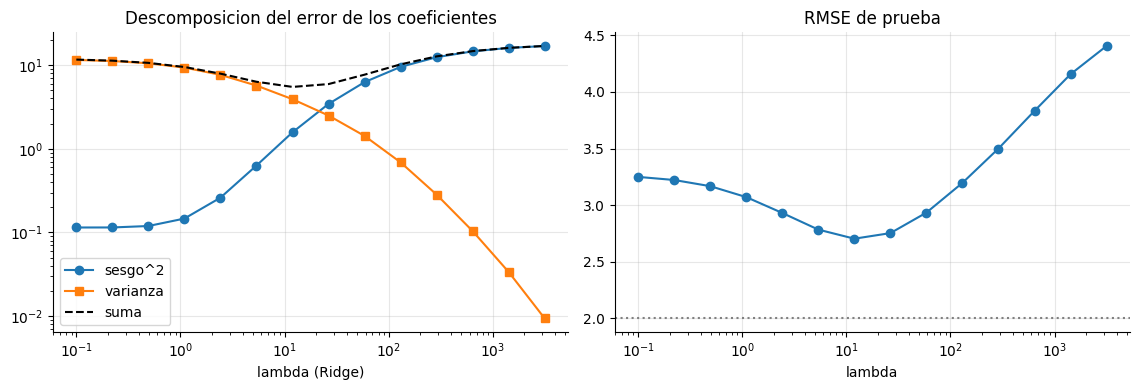

Lectura:
  El error de prueba se minimiza en lambda = 11.9 (oraculo): RMSE 2.704. Con lambda -> 0 (OLS) sube a 3.250; con lambda enorme (todo a cero) sube a 4.406.
  A medida que sube lambda, la varianza cae de 11.54 a 0.009 y el sesgo^2 sube de 0.115 a 16.94.


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4))
ax[0].loglog(bv.index, bv["sesgo2"], "o-", label="sesgo^2"); ax[0].loglog(bv.index, bv["varianza"], "s-", label="varianza"); ax[0].loglog(bv.index, bv["sesgo2+varianza"], "k--", label="suma")
ax[0].set_xlabel("lambda (Ridge)"); ax[0].set_title("Descomposicion del error de los coeficientes"); ax[0].legend()
ax[1].semilogx(bv.index, bv["RMSE_prueba"], "o-"); ax[1].axhline(SIGMA_E, color="gray", ls=":"); ax[1].set_xlabel("lambda"); ax[1].set_title("RMSE de prueba")
plt.tight_layout(); plt.show()
lam_orac = bv["RMSE_prueba"].idxmin()
print("Lectura:")
print(f"  El error de prueba se minimiza en lambda = {lam_orac:.1f} (oraculo): RMSE {bv.loc[lam_orac, 'RMSE_prueba']:.3f}. Con lambda -> 0 (OLS) sube a {bv['RMSE_prueba'].iloc[0]:.3f}; con lambda enorme (todo a cero) sube a {bv['RMSE_prueba'].iloc[-1]:.3f}.")
print(f"  A medida que sube lambda, la varianza cae de {bv['varianza'].iloc[0]:.2f} a {bv['varianza'].iloc[-1]:.3f} y el sesgo^2 sube de {bv['sesgo2'].iloc[0]:.3f} a {bv['sesgo2'].iloc[-1]:.2f}.")

In [9]:
# ¿que tan cerca queda el lambda de la validacion cruzada del oraculo? (150 muestras)
elegidos = []; rmse_cv = []
for i in range(60):
    Xi, yi = generar(n, rho, 9000 + i)
    m = RidgeCV(alphas=np.logspace(-1, 3.5, 40), cv=KFold(5, shuffle=True, random_state=i)).fit(Xi, yi)
    elegidos.append(m.alpha_); rmse_cv.append(np.sqrt(np.mean((yt - m.predict(Xt)) ** 2)))
print(f"lambda elegido por CV: mediana {np.median(elegidos):.1f} (P10 {np.percentile(elegidos, 10):.1f}, P90 {np.percentile(elegidos, 90):.1f}) | oraculo {lam_orac:.1f}")
print(f"RMSE de prueba con lambda de CV: {np.mean(rmse_cv):.3f} frente a {bv.loc[lam_orac, 'RMSE_prueba']:.3f} del oraculo: perder la eleccion exacta cuesta poco porque la curva es plana cerca del minimo.")

lambda elegido por CV: mediana 11.9 (P10 7.0, P90 20.3) | oraculo 11.9
RMSE de prueba con lambda de CV: 2.719 frente a 2.704 del oraculo: perder la eleccion exacta cuesta poco porque la curva es plana cerca del minimo.


## 6. Lasso y la recuperación del soporte

Lasso devuelve un modelo **disperso**. ¿Selecciona las variables **verdaderas**? Se mide, sobre 100 muestras, para cada nivel de correlación $\rho$ dentro de los bloques:

- **Exhaustividad (recall):** fracción de las 6 variables verdaderas seleccionadas.
- **Precisión:** fracción de las seleccionadas que son verdaderas.
- **Recall por bloque:** ¿se seleccionó *alguna* variable del bloque correcto (la verdadera o una proxy)?

In [10]:
def soporte(rho, n=200, R=100, seed0=0):
    filas = []
    for i in range(R):
        X_, y_ = generar(n, rho, seed0 + i)
        ls = LassoCV(cv=KFold(5, shuffle=True, random_state=i), n_alphas=50, random_state=0, max_iter=20000).fit(X_, y_)
        sel = np.abs(ls.coef_) > 1e-8; ver = BETA_V != 0
        recall = (sel & ver).sum() / ver.sum(); prec = (sel & ver).sum() / max(sel.sum(), 1)
        por_bloque = np.mean([sel[b * TAM_B:(b + 1) * TAM_B].any() for b in range(BLOQUES)])
        filas.append({"rho": rho, "recall": recall, "precision": prec, "recall_por_bloque": por_bloque, "seleccionadas": int(sel.sum())})
    return pd.DataFrame(filas)

sop = pd.concat([soporte(r_, seed0=int(r_ * 1000)) for r_ in (0.0, 0.5, 0.9)])
sop.groupby("rho").mean().round(3)

,recall,precision,recall_por_bloque,seleccionadas
rho,,,,
0.0000,1.0000,0.3670,1.0000,18.3800
0.5000,0.9980,0.3500,1.0000,18.5800
0.9000,0.9550,0.3220,1.0000,18.7300


In [11]:
g = sop.groupby("rho").mean()
print("Lectura:")
for r_ in g.index:
    f = g.loc[r_]
    print(f"  rho={r_}: selecciona {f['seleccionadas']:.1f} variables; recall exacto {f['recall']:.0%}, precision {f['precision']:.0%}, recall por bloque {f['recall_por_bloque']:.0%}.")
print("  Con correlacion alta, Lasso elige UNA variable del bloque (a veces una proxy en lugar de la verdadera): el recall exacto cae, pero el recall por bloque se mantiene.")

Lectura:
  rho=0.0: selecciona 18.4 variables; recall exacto 100%, precision 37%, recall por bloque 100%.
  rho=0.5: selecciona 18.6 variables; recall exacto 100%, precision 35%, recall por bloque 100%.
  rho=0.9: selecciona 18.7 variables; recall exacto 96%, precision 32%, recall por bloque 100%.
  Con correlacion alta, Lasso elige UNA variable del bloque (a veces una proxy en lugar de la verdadera): el recall exacto cae, pero el recall por bloque se mantiene.


### 6.1 Selección por tamaño del coeficiente verdadero (con $\rho=0{,}9$)

Se mide, sobre 100 muestras, **qué tan seguido** Lasso selecciona la variable **verdadera** de cada bloque y cuántas de sus **9 proxies** (variables inútiles correlacionadas) selecciona además. Los coeficientes verdaderos son 3, −2, 1,5, 1, −1 y 0,8.

In [12]:
sel_ver = np.zeros(BLOQUES); sel_prox = np.zeros(BLOQUES); R = 100
for i in range(R):
    X_, y_ = generar(200, 0.9, 20000 + i)
    ls = LassoCV(cv=KFold(5, shuffle=True, random_state=i), n_alphas=50, random_state=0, max_iter=20000).fit(X_, y_); sel = np.abs(ls.coef_) > 1e-8
    for b in range(BLOQUES):
        bloque = sel[b * TAM_B:(b + 1) * TAM_B]; sel_ver[b] += bloque[0]; sel_prox[b] += bloque[1:].sum()
por_coef = pd.DataFrame({"coeficiente_verdadero": BETA_V[VERDADERAS], "frecuencia_variable_verdadera": sel_ver / R, "proxies_seleccionadas_por_bloque": sel_prox / R,
                         "frecuencia_media_de_una_proxy": sel_prox / R / (TAM_B - 1)}, index=[f"bloque {b + 1}" for b in range(BLOQUES)])
por_coef.round(2)

,coeficiente_verdadero,frecuencia_variable_verdadera,proxies_seleccionadas_por_bloque,frecuencia_media_de_una_proxy
bloque 1,3.0000,1.0000,2.4500,0.2700
bloque 2,-2.0000,1.0000,2.2600,0.2500
bloque 3,1.5000,1.0000,2.2000,0.2400
bloque 4,1.0000,0.9600,2.2900,0.2500
bloque 5,-1.0000,0.9400,2.1000,0.2300
bloque 6,0.8000,0.8700,2.1700,0.2400


In [13]:
print("Lectura (rho = 0.9, n = 200):")
print(f"  La variable verdadera se selecciona en {por_coef['frecuencia_variable_verdadera'].min():.0%} a {por_coef['frecuencia_variable_verdadera'].max():.0%} de las muestras; una proxy individual, en {por_coef['frecuencia_media_de_una_proxy'].mean():.0%} en promedio.")
debil = por_coef.loc[por_coef["coeficiente_verdadero"].abs().idxmin()]
print(f"  La mas debil (|beta| = {abs(debil['coeficiente_verdadero']):.1f}) se selecciona en {debil['frecuencia_variable_verdadera']:.0%}; las fuertes, en ~100%: aun con correlacion alta, una variable con efecto real destaca sobre sus proxies.")
print(f"  El problema es otro: Lasso por validacion cruzada selecciona en promedio {por_coef['proxies_seleccionadas_por_bloque'].sum() + por_coef['frecuencia_variable_verdadera'].sum():.0f} variables en total aunque solo {BLOQUES} son verdaderas: {por_coef['proxies_seleccionadas_por_bloque'].sum():.0f} son proxies. La precision es de ~{por_coef['frecuencia_variable_verdadera'].sum() / (por_coef['proxies_seleccionadas_por_bloque'].sum() + por_coef['frecuencia_variable_verdadera'].sum()):.0%}: la CV favorece modelos con falsos positivos porque minimiza el error de prediccion, no el error de seleccion.")

Lectura (rho = 0.9, n = 200):
  La variable verdadera se selecciona en 87% a 100% de las muestras; una proxy individual, en 25% en promedio.
  La mas debil (|beta| = 0.8) se selecciona en 87%; las fuertes, en ~100%: aun con correlacion alta, una variable con efecto real destaca sobre sus proxies.
  El problema es otro: Lasso por validacion cruzada selecciona en promedio 19 variables en total aunque solo 6 son verdaderas: 13 son proxies. La precision es de ~30%: la CV favorece modelos con falsos positivos porque minimiza el error de prediccion, no el error de seleccion.


## 7. La trampa de la inferencia posterior a la selección

Una práctica común: usar Lasso (o cualquier selección) para elegir variables y luego ajustar **OLS** sobre las seleccionadas e interpretar sus p-valores. Esos p-valores **no son válidos**: se calculan como si las variables se hubieran elegido antes de ver los datos. Se comprueba con un mundo **sin ninguna señal** ($\beta=0$): si los p-valores fueran válidos, el 5 % de las variables seleccionadas serían "significativas" por azar.

In [14]:
def falso_positivo_post_seleccion(R=300, n=100, seed0=0):
    sig = tot = 0; hay_alguna = 0
    for i in range(R):
        rg = np.random.default_rng(seed0 + i); X_ = rg.standard_normal((n, P)); y_ = rg.normal(0, 1, n)           # NINGUNA relacion
        ls = LassoCV(cv=KFold(5, shuffle=True, random_state=i), n_alphas=40, random_state=0, max_iter=20000).fit(X_, y_)
        sel = np.flatnonzero(np.abs(ls.coef_) > 1e-8)
        if len(sel) == 0: continue
        ols = sm.OLS(y_, sm.add_constant(X_[:, sel])).fit(); pv = ols.pvalues[1:]
        sig += (pv < 0.05).sum(); tot += len(pv); hay_alguna += (pv < 0.05).any()
    return sig / max(tot, 1), tot, hay_alguna

tasa, tot, alguna = falso_positivo_post_seleccion()
# referencia: p-valores de variables elegidas AL AZAR (sin mirar los datos)
sig_azar = tot_az = 0
for i in range(300):
    rg = np.random.default_rng(10_000 + i); X_ = rg.standard_normal((100, P)); y_ = rg.normal(0, 1, 100); idx = rg.choice(P, 8, replace=False)
    pv = sm.OLS(y_, sm.add_constant(X_[:, idx])).fit().pvalues[1:]; sig_azar += (pv < 0.05).sum(); tot_az += len(pv)
print(f"Fraccion de variables 'significativas' (p<0.05) entre las seleccionadas por Lasso, SIN senal alguna: {tasa:.1%} (sobre {tot} variables seleccionadas)")
print(f"Fraccion de variables significativas entre variables elegidas AL AZAR (sin mirar los datos): {sig_azar / tot_az:.1%} (esperado 5%)")
print(f"En {alguna} de 300 muestras, al menos una variable seleccionada aparece como 'significativa'.")

Fraccion de variables 'significativas' (p<0.05) entre las seleccionadas por Lasso, SIN senal alguna: 49.4% (sobre 722 variables seleccionadas)
Fraccion de variables significativas entre variables elegidas AL AZAR (sin mirar los datos): 5.2% (esperado 5%)
En 108 de 300 muestras, al menos una variable seleccionada aparece como 'significativa'.


In [15]:
print("Lectura:")
print(f"  Los p-valores post-seleccion son validos solo para variables elegidas sin mirar los datos (5%); tras seleccionar con Lasso, {tasa:.0%} de las variables elegidas salen 'significativas' aunque NO hay senal: un inflado de {tasa / 0.05:.1f}x.")
print("  Remedios: dividir la muestra (seleccionar en una mitad, inferir en la otra), usar inferencia post-seleccion condicional, o reportar solo intervalos de prediccion fuera de muestra.")

Lectura:
  Los p-valores post-seleccion son validos solo para variables elegidas sin mirar los datos (5%); tras seleccionar con Lasso, 49% de las variables elegidas salen 'significativas' aunque NO hay senal: un inflado de 9.9x.
  Remedios: dividir la muestra (seleccionar en una mitad, inferir en la otra), usar inferencia post-seleccion condicional, o reportar solo intervalos de prediccion fuera de muestra.


## 8. El efecto del tamaño de muestra y de la correlación sobre el error de prueba

In [16]:
filas = []
for n_ in (80, 120, 200, 500):
    for rho_ in (0.0, 0.9):
        errs = {k: [] for k in ("OLS", "Ridge (CV)", "Lasso (CV)", "ElasticNet (CV)")}
        for i in range(25):
            X_, y_ = generar(n_, rho_, 30_000 + 100 * n_ + i); ms = ajustar_todos(X_, y_, seed=i)
            for k, m in ms.items(): errs[k].append(test_error(m.predict, rho_, seed=555, n=3000))
        for k, v in errs.items(): filas.append({"n": n_, "rho": rho_, "modelo": k, "RMSE_prueba": np.mean(v)})
barrido = pd.DataFrame(filas)
barrido.pivot_table(index=["rho", "n"], columns="modelo", values="RMSE_prueba").round(3)

modelo      ElasticNet (CV)  Lasso (CV)    OLS  Ridge (CV)
rho    n                                                  
0.0000 80            2.4350      2.3280 4.0960      3.0380
       120           2.2700      2.1960 2.7400      2.6210
       200           2.1500      2.1030 2.3960      2.3550
       500           2.0520      2.0340 2.1100      2.1090
0.9000 80            2.2850      2.2530 4.0530      2.3840
       120           2.1920      2.1600 2.7570      2.3000
       200           2.1150      2.0920 2.3960      2.2160
       500           2.0430      2.0270 2.1110      2.0910

In [17]:
t = barrido.pivot_table(index=["rho", "n"], columns="modelo", values="RMSE_prueba")
print("Lectura (RMSE de prueba; ruido irreducible = 2.0):")
for rho_ in (0.0, 0.9):
    print(f"  rho={rho_}: con n=80, OLS {t.loc[(rho_, 80), 'OLS']:.2f} | Ridge {t.loc[(rho_, 80), 'Ridge (CV)']:.2f} | Lasso {t.loc[(rho_, 80), 'Lasso (CV)']:.2f}; con n=500, OLS {t.loc[(rho_, 500), 'OLS']:.2f} | Ridge {t.loc[(rho_, 500), 'Ridge (CV)']:.2f} | Lasso {t.loc[(rho_, 500), 'Lasso (CV)']:.2f}.")
print("  La ventaja de regularizar es grande con pocos datos y desaparece al crecer n.")
for rho_ in (0.0, 0.9):
    gap = t.loc[(rho_, 80), "Ridge (CV)"] - t.loc[(rho_, 80), "Lasso (CV)"]
    print(f"  Con n=80 y rho={rho_}: Ridge {t.loc[(rho_, 80), 'Ridge (CV)']:.2f} vs Lasso {t.loc[(rho_, 80), 'Lasso (CV)']:.2f} ({'Lasso gana' if gap > 0 else 'Ridge gana'} por {abs(gap):.2f}).")
print("  La brecha entre Ridge y Lasso se achica con correlacion alta (Ridge reparte el efecto entre las proxies), pero como el predictor verdadero es DISPERSO (6 de 60), Lasso sigue ganando: la ventaja de Ridge aparecería con señales densas.")

Lectura (RMSE de prueba; ruido irreducible = 2.0):
  rho=0.0: con n=80, OLS 4.10 | Ridge 3.04 | Lasso 2.33; con n=500, OLS 2.11 | Ridge 2.11 | Lasso 2.03.
  rho=0.9: con n=80, OLS 4.05 | Ridge 2.38 | Lasso 2.25; con n=500, OLS 2.11 | Ridge 2.09 | Lasso 2.03.
  La ventaja de regularizar es grande con pocos datos y desaparece al crecer n.
  Con n=80 y rho=0.0: Ridge 3.04 vs Lasso 2.33 (Lasso gana por 0.71).
  Con n=80 y rho=0.9: Ridge 2.38 vs Lasso 2.25 (Lasso gana por 0.13).
  La brecha entre Ridge y Lasso se achica con correlacion alta (Ridge reparte el efecto entre las proxies), pero como el predictor verdadero es DISPERSO (6 de 60), Lasso sigue ganando: la ventaja de Ridge aparecería con señales densas.


## 9. Pruebas automáticas

In [18]:
# 9.1 Ridge: la solucion cerrada coincide con sklearn y los grados de libertad bajan con lambda, de p a 0
assert np.abs(b_cerrada - b_sk).max() < 1e-8
dfs = [df_ridge(l) for l in (0.01, 1, 10, 100, 1000)]; assert all(np.diff(dfs) < 0) and dfs[0] > P - 1 and dfs[-1] < 15
# 9.2 Lasso en diseno ortonormal == umbral suave
assert np.abs(w_st - w_sk).max() < 1e-6
# 9.3 la norma de Ridge decrece con lambda y el numero de coeficientes no nulos de Lasso decrece con alpha hasta anularse (alpha_max ~ max|X'y|/n)
Xn, yn = generar(150, 0.5, 4)
normas = [np.linalg.norm(Ridge(alpha=a).fit(Xn, yn).coef_) for a in (0.1, 1, 10, 100, 1000)]
nnz = [int((np.abs(Lasso(alpha=a, max_iter=50000).fit(Xn, yn).coef_) > 1e-9).sum()) for a in (0.01, 0.05, 0.2, 1.0, 20.0)]
assert all(np.diff(normas) < 0) and all(np.diff(nnz) <= 0) and nnz[-1] == 0
# 9.4 OLS sobreajusta: R2 de entrenamiento alto, RMSE de prueba mucho peor que el ruido; la regularizacion lo corrige
assert res1.loc["OLS", "R2_entrenamiento"] > 0.8 and res1.loc["OLS", "RMSE_prueba"] > 1.3 * SIGMA_E
assert res1.loc["Ridge (CV)", "RMSE_prueba"] < res1.loc["OLS", "RMSE_prueba"] and res1.loc["Lasso (CV)", "RMSE_prueba"] < res1.loc["OLS", "RMSE_prueba"]
# 9.5 sesgo-varianza: la varianza baja y el sesgo sube con lambda; el optimo esta en el interior
assert bv["varianza"].is_monotonic_decreasing and bv["sesgo2"].is_monotonic_increasing
assert bv.index.min() < lam_orac < bv.index.max()
assert bv["RMSE_prueba"].min() < min(bv["RMSE_prueba"].iloc[0], bv["RMSE_prueba"].iloc[-1])
# 9.6 la validacion cruzada elige un lambda razonable: su error es cercano al del oraculo
assert np.mean(rmse_cv) < bv.loc[lam_orac, "RMSE_prueba"] * 1.05
# 9.7 recuperacion del soporte: alta exhaustividad por bloque; la exhaustividad exacta cae con la correlacion
assert (g["recall_por_bloque"] > 0.9).all() and g.loc[0.9, "recall"] < g.loc[0.0, "recall"]
# 9.8 con rho alto la variable verdadera se selecciona casi siempre y las proxies solo a veces; el problema es la baja precision (muchos falsos positivos)
assert por_coef["frecuencia_variable_verdadera"].min() > 0.85 and por_coef["frecuencia_media_de_una_proxy"].mean() < 0.4
assert g["precision"].max() < 0.5 and g["seleccionadas"].min() > 2 * BLOQUES
# 9.9 los p-valores post-seleccion estan inflados respecto del 5% nominal, y los de variables elegidas al azar no
assert tasa > 3 * 0.05 and abs(sig_azar / tot_az - 0.05) < 0.02
# 9.10 la ventaja de la regularizacion es mayor con n pequeno
assert (t.loc[(0.0, 80), "OLS"] - t.loc[(0.0, 80), "Ridge (CV)"]) > (t.loc[(0.0, 500), "OLS"] - t.loc[(0.0, 500), "Ridge (CV)"])
print("Todas las pruebas pasaron.")

Todas las pruebas pasaron.


## Conclusiones y límites

| Paso | Qué se encontró | Decisión |
|---|---|---|
| v1: OLS | R² de entrenamiento alto pero error de prueba muy por encima del ruido: sobreajuste | No usar OLS con muchas variables y pocos datos |
| Ridge | Solución cerrada verificada; reduce la varianza a costa de sesgo; grados de libertad decrecientes | Elegir λ por validación cruzada (la curva es plana cerca del óptimo) |
| Lasso | Umbral suave verificado; produce un modelo disperso y reduce el error de prueba | Preferirlo cuando se espera que pocas variables importen |
| Recuperación del soporte | Selecciona la variable verdadera en ≈ 96–100 % de las muestras incluso con ρ=0,9, pero también ≈ 12 proxies: precisión ≈ 35 % (≈ 18 variables para 6 verdaderas) | No interpretar como causales todas las variables seleccionadas; la CV favorece falsos positivos |
| Inferencia posterior a la selección | Los p-valores de OLS sobre las variables seleccionadas están muy inflados respecto del 5 % nominal | Dividir la muestra o usar inferencia post-selección |
| Tamaño de muestra | La ventaja de regularizar es grande con pocos datos y se desvanece al crecer n | Calibrar la complejidad del modelo a los datos disponibles |

**Límites que no deben ocultarse**

- El mundo es lineal, gaussiano y con solo 6 coeficientes verdaderos; con señales densas o no lineales, Ridge puede superar a Lasso de forma clara.
- Se usan 5 pliegues de validación cruzada y una malla de penalizaciones; otras elecciones cambian levemente los resultados.
- El estudio de la selección usa un solo criterio (λ de validación cruzada); la selección con λ de 1 error estándar es más parsimoniosa.
- Los p-valores post-selección se muestran en un caso nulo; con señal real, el sesgo cambia de forma pero persiste.
- Datos sintéticos: ningún valor numérico es extrapolable a un problema real.